# Effect of Noise Variance on MNIST Flow Matching

In [1]:
import time

import torch 
from torch import nn, Tensor
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid
import numpy as np

import matplotlib.pyplot as plt
from sklearn.datasets import make_moons

In [ ]:
plt.rcParams.update({
    'figure.dpi': 150,
    'savefig.dpi': 150,
    'font.size': 13,
    'axes.titlesize': 15,
    'axes.labelsize': 13,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'legend.fontsize': 11,
    'figure.titlesize': 17,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'lines.linewidth': 2.0,
})

In [2]:
device = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')

### Load MNIST dataset

In [3]:


# Normalize pixel values from [0, 1] to [-1, 1] so the data matches a standard
# Gaussian source for flow matching.
transform = transforms.Compose([
    transforms.ToTensor(),
])

train_dataset = datasets.MNIST(root='../../data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='../../data', train=False, download=True, transform=transform)

batch_size = 128
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f'Train samples: {len(train_dataset)}, Test samples: {len(test_dataset)}')
images, labels = next(iter(train_loader))
print(f'Batch images shape: {images.shape}, labels shape: {labels.shape}')

Train samples: 60000, Test samples: 10000
Batch images shape: torch.Size([128, 1, 28, 28]), labels shape: torch.Size([128])


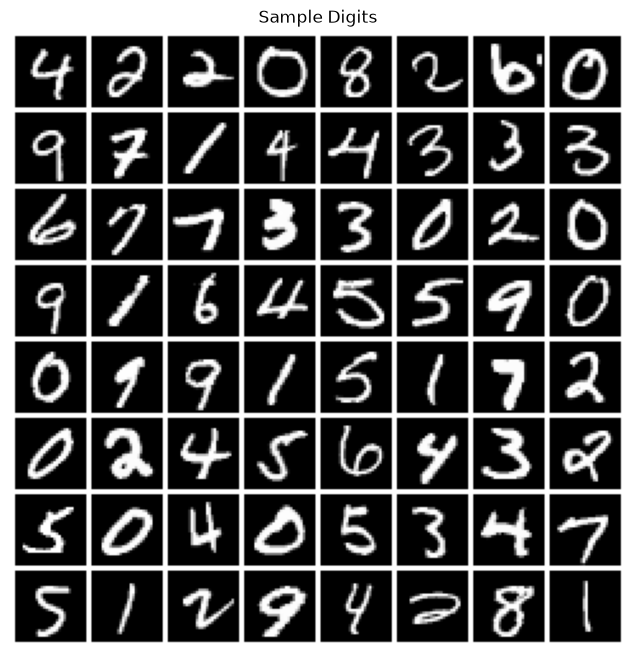

In [4]:
## Display some sample digits

def show_samples(images: Tensor, nrow: int=8, ax=None):
    # images = (images + 1) / 2  # denormalize
    images = images.clamp(0, 1)
    grid = make_grid(images[:nrow**2], nrow, padding=2, pad_value=1)
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 8))
    ax.set_aspect('equal')
    ax.set_title('Sample Digits')
    ax.imshow(grid.permute(1, 2, 0).cpu())
    ax.axis('off')
    return ax

show_samples(images);

In [5]:
class Flow(nn.Module):

    def __init__(self, dim: int=28*28, h: int=128):
        super().__init__()
        self.dim = dim
        self.h = h

        self.net = nn.Sequential(
            nn.Linear(dim+1, 2*h),
            nn.ReLU(),
            nn.Linear(2*h, h),
            nn.ReLU(),
            nn.Linear(h, 2*h),
            nn.ReLU(),
            nn.Linear(2*h, dim),
        )
    def forward(self, x, t):
        x_t = torch.cat([x, t], dim=1)
        return self.net(x_t)

    def step(self, x_t: Tensor, t_start: float, t_end: float):
        t_start = t_start.view(1, 1).expand(x_t.shape[0], 1)
        dt = t_end - t_start
        return x_t + dt * self(x_t + self(x_t, t=t_start)*dt/2, t=(t_start + t_end)/2)

    def inverse_step(self, x_t: Tensor, t_start: float, t_end: float):
        t_end = t_end.view(1, 1).expand(x_t.shape[0], 1)
        dt = t_end - t_start
        return x_t - dt * self(x_t, t=t_end)



### Effect of noise variance

The source is $x_0 \sim \mathcal{N}(0.5,\,\sigma^2 I)$. Small $\sigma$ gives short, nearly straight paths that are easy to learn but constrain the flow to start close to the data. Large $\sigma$ gives longer, noisier paths that can generate more diverse samples but are harder to fit. We sweep $\sigma$ across an order of magnitude to find the sweet spot.

In [6]:
def train_flow(flow, train_loader, n_epochs=50, lr=1e-3, sigma_noise=0.2, device=device):
    losses = []
    opt = torch.optim.Adam(flow.parameters(), lr=lr)
    for e in range(n_epochs):
        current_loss = 0.0
        for i, (x, _) in enumerate(train_loader):
            x_1 = x.view(-1, 784).to(device)

            t = torch.rand(x.shape[0], 1, device=x_1.device)
            x_0 = torch.randn_like(x_1)*sigma_noise + 0.5
            dx_t = x_1 - x_0
            x_t = (1-t)*x_0 + t * x_1
            flow_pred = flow(x_t, t)

            loss = (flow_pred - dx_t).pow(2).sum(dim=1).mean()
            loss.backward()
            opt.step()
            opt.zero_grad()

            current_loss += loss.item()
        avg_loss = current_loss / len(train_loader)
        losses.append(avg_loss)
        print(f'\r[{100*(e+1)/n_epochs:.0f}%] Epoch {e+1}/{n_epochs}  loss: {avg_loss:.4f}', end='', flush=True)

    return losses

In [7]:
SIGMAS = np.logspace(-2, 0, 6)
sigma_losses = {}
sigma_flows = {}
for sigma in SIGMAS:
    flow = Flow(h=256).to(device)
    losses = train_flow(flow, train_loader, n_epochs=50, lr=1e-3, sigma_noise=sigma, device=device)
    sigma_losses[sigma] = losses
    sigma_flows[sigma] = flow
    print(f'Training completed for sigma={sigma}. Final loss: {losses[-1]:.4f}')



[100%] Epoch 50/50  loss: 7.6624Training completed for sigma=0.01. Final loss: 7.6624
[100%] Epoch 50/50  loss: 8.5323Training completed for sigma=0.025118864315095794. Final loss: 8.5323
[100%] Epoch 50/50  loss: 12.9408Training completed for sigma=0.06309573444801933. Final loss: 12.9408
[100%] Epoch 50/50  loss: 34.0840Training completed for sigma=0.15848931924611143. Final loss: 34.0840
[100%] Epoch 50/50  loss: 138.3533Training completed for sigma=0.3981071705534973. Final loss: 138.3533
[100%] Epoch 50/50  loss: 735.6465Training completed for sigma=1.0. Final loss: 735.6465


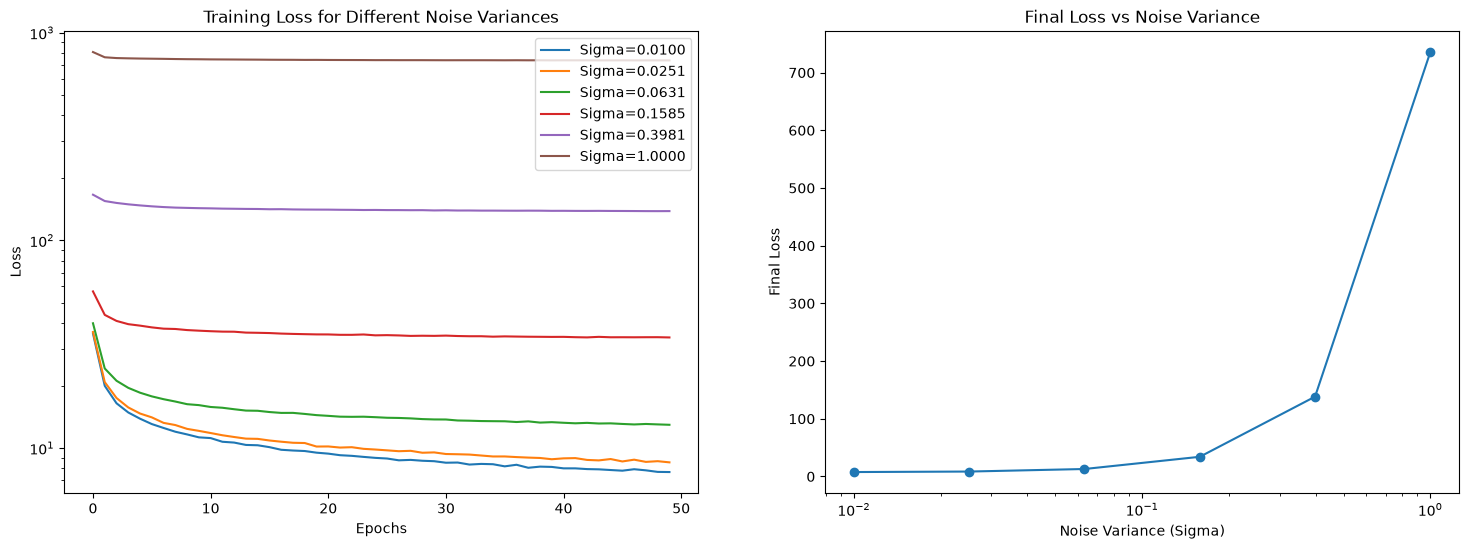

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(18, 6))
for sigma, losses in sigma_losses.items():
    ax[0].plot(losses, label=f'Sigma={sigma:.4f}')
ax[0].set_yscale('log')
ax[0].set_title('Training Loss for Different Noise Variances')
ax[0].set_xlabel('Epochs')
ax[0].set_ylabel('Loss')
ax[0].legend()

final_losses = [losses[-1] for losses in sigma_losses.values()]
ax[1].plot(SIGMAS, final_losses, marker='o')
ax[1].set_xscale('log')
ax[1].set_title('Final Loss vs Noise Variance')
ax[1].set_xlabel('Noise Variance (Sigma)')
ax[1].set_ylabel('Final Loss')

plt.show()

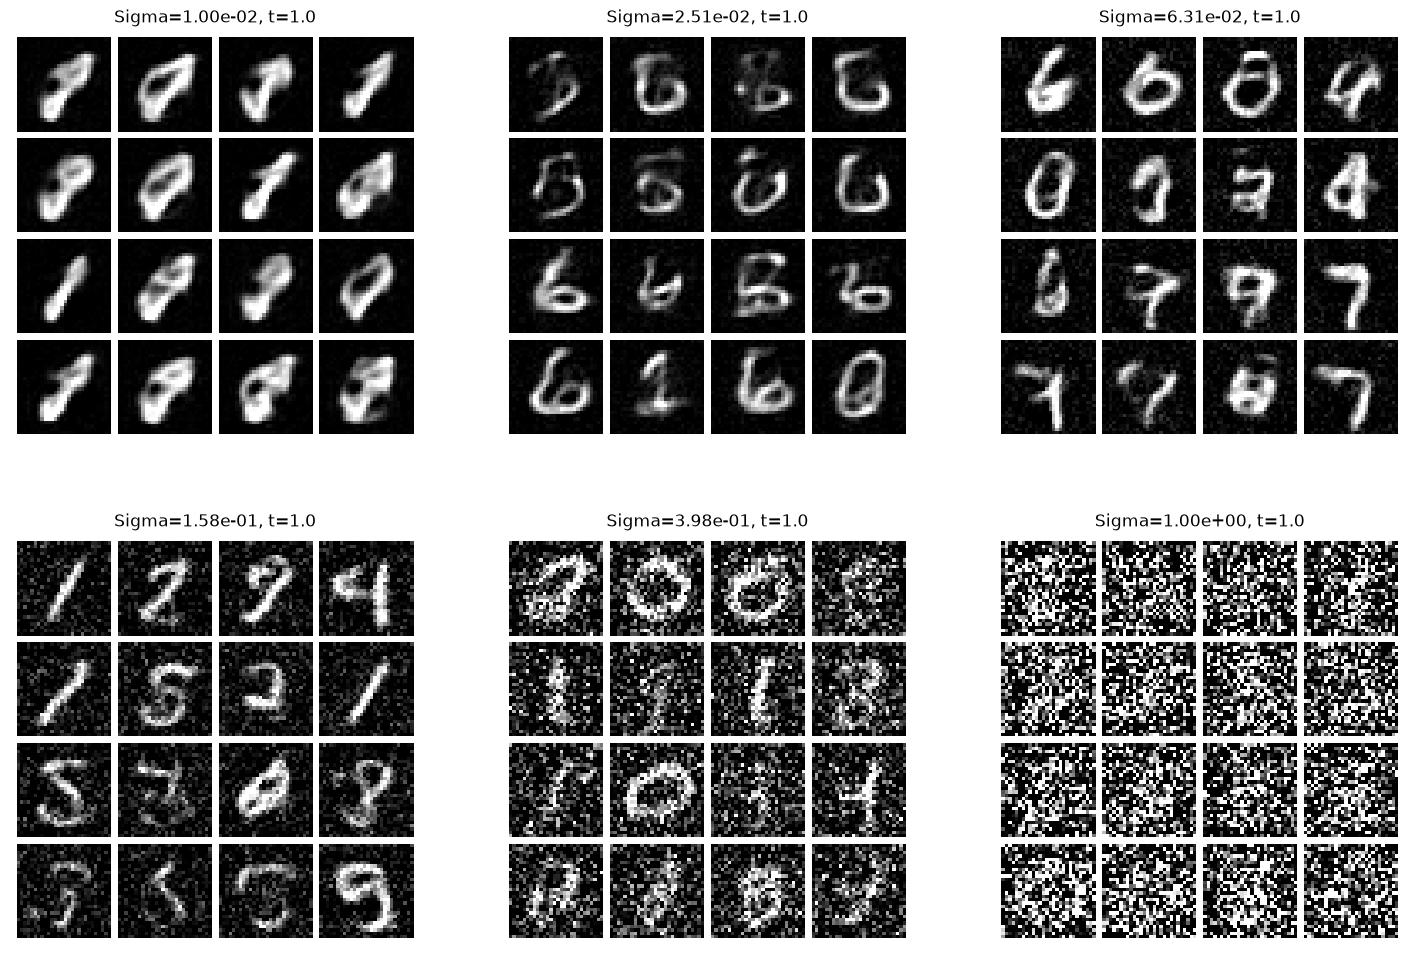

In [9]:
fig, ax = plt.subplots(2, 3, figsize=(18, 12))
ax = ax.reshape(-1)
for j, (sigma, model) in enumerate(sigma_flows.items()):
    x = torch.randn(16, 784).to(device)*sigma + 0.5
    n_steps = 100
    time_steps = torch.linspace(0, 1.0, n_steps + 1)

    with torch.no_grad():
        for i in range(n_steps):
            x = model.step(x_t=x, t_start=time_steps[i].to(device), t_end=time_steps[i + 1].to(device))

    show_samples(x.detach().view(-1, 1, 28, 28), nrow=4, ax=ax[j])
    ax[j].set_title(f'Sigma={sigma:.2e}, t=1.0')

plt.show()

Error descreases with Sigma, but at some point the diversity of the generated samples decreases. To high variance, the model do not learn well, to low variance, the model learns well but the generated samples are not diverse.